## 04 Pair Programming Exercise: 
# Ergodicity Game 
Consider the following game: 
You start with a budget of 100€. You flip a fair coin (50% chance head and 50% chance tail). If the coin shows “heads” you win 50% of your budget. If it shows “tails,” you lose 40% of your budget. (Think by yourself! Do not use ChatGPT)

1. What is the expected win (or loss) for one coin flip (one bet)? Calculate it in Python. 

In [75]:
budget = 100
w = 0.5*budget
l = -0.4*budget

2. Create a function coin_flip that returns randomly in 50% probability the string “heads” and with 50% the string “tails”. You can use from the random package the random function. First import it and the use it like this: from random import random random() This will give you a random float between 0 and 1 

In [76]:
import random as rand

def coin_flip() :
    flip = rand.random()
    if flip > 0.5:
        result = "heads"
    else:
         result = "tails"
    return result

print(coin_flip())



tails


3. Create a function one_bet with the parameter budget that returns the remaining budget (depending on a coin flip).

In [77]:
def onebet(b):
    result=coin_flip()
    if result == "heads":
        budget = b+b*0.5
    else:
        budget = b-b*0.4
    return budget

print(onebet(100))


60.0


4. What happens if you play the bet multiple times sequentially? So, after you win or lose, you can bet on the remaining budget again and again. Create a Python function multiple_bets that returns a list of multiple consecutive remaining budgets in a list. In each round, you bet the complete budget. The starting budget should be 100. However, each consecutive bet uses the remaining budget for betting, depending on the result of the prior bet. The function should have the parameter number_of_bets with a default value of 50. 

In [84]:
def multiple_bets(budget, number_of_bets=50):
    series=[budget]
    for i in range(number_of_bets):
       budget = onebet(budget)
       series.append(budget)
    return series

print(multiple_bets(100))

[100, 150.0, 90.0, 135.0, 202.5, 303.75, 455.625, 683.4375, 1025.15625, 1537.734375, 922.640625, 553.5843749999999, 830.3765624999999, 498.2259374999999, 747.3389062499998, 448.40334374999986, 269.0420062499999, 161.42520374999992, 242.13780562499988, 363.20670843749986, 217.9240250624999, 130.75441503749994, 78.45264902249997, 47.07158941349998, 28.242953648099988, 16.94577218885999, 25.418658283289986, 15.25119496997399, 22.876792454960984, 13.726075472976591, 20.589113209464887, 30.883669814197333, 46.325504721296, 27.795302832777598, 41.6929542491664, 25.01577254949984, 15.009463529699904, 9.005678117819942, 13.508517176729914, 8.105110306037947, 12.15766545905692, 7.294599275434152, 10.941898913151228, 6.565139347890736, 3.9390836087344416, 5.908625413101662, 3.545175247860997, 2.1271051487165984, 3.1906577230748976, 1.9143946338449385, 1.148636780306963]


5. Plot the list of the returns of multiple_bets  with the Matplotlib library as a line chart. You can import Matplotlib like that  import matplotlib.pyplot as plt and plot a list like this: plt.plot(my_list) Rerun it multiple times to see how the chart changes. 

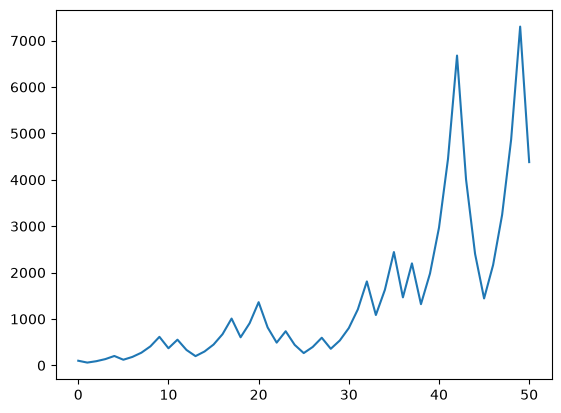

In [88]:
import matplotlib.pyplot as plt

plt.plot(multiple_bets(100))
plt.show()

6. Create a function simulation with a parameter simulation_runs with a default parameter of 1000 and number_of_bets with a default value 50. For each simulation run, it should add the final budget of the multiple_bets function to a list. After all simulation runs, it should return the list of all the final budgets. 

In [90]:
def simulation(budget, simulations = 1000, number_of_bets = 50):
    final_budgets = []
    for i in range(simulations):
        final_budgets.append(multiple_bets(budget, number_of_bets)[-1])
    return final_budgets
simulation(100)


[2.8715919507674084,
 10954.2539625832,
 0.18378188484911406,
 17.947449692296303,
 112.17156057685196,
 0.0735127539396456,
 2.8715919507674075,
 1.148636780306963,
 2.8715919507674075,
 7.17897987691852,
 1.1486367803069637,
 1.1486367803069633,
 1.1486367803069633,
 44.86862423074075,
 112.17156057685192,
 0.011762040630343296,
 17.947449692296292,
 17.947449692296306,
 0.011762040630343298,
 2.8715919507674084,
 2.8715919507674066,
 1.1486367803069637,
 2.8715919507674075,
 1752.68063401331,
 280.4289014421299,
 7.17897987691852,
 7.17897987691852,
 17.9474496922963,
 2.8715919507674075,
 17.947449692296306,
 1.148636780306963,
 701.0722536053245,
 1.1486367803069633,
 0.07351275393964561,
 7.178979876918519,
 0.029405101575858253,
 0.18378188484911406,
 701.0722536053248,
 112.17156057685187,
 0.4594547121227852,
 1.1486367803069633,
 701.0722536053242,
 17.9474496922963,
 280.42890144212964,
 17.94744969229629,
 0.0018819265008549275,
 1752.68063401331,
 112.1715605768519,
 701.0

7. Run the simulation with 1000 runs and 50 bets per run. Calculate the mean and median of the final budgets. You can use the Python package statistics: import statistics statistics.mean(my_list) statistics.median(my_list) Would you play the game? Would you play the game if the starting budget is all your money? 

In [136]:
import statistics as stat
stat_sim=simulation(100)
print(
    stat.mean(stat_sim),
    stat.median(stat_sim)
    )



551.5149042038463 7.17897987691852


8. Use Matplotlib to plot a histogram of all runs. You can do this with  plt.hist(my_list, bins=100) You can also change the number of bins. 

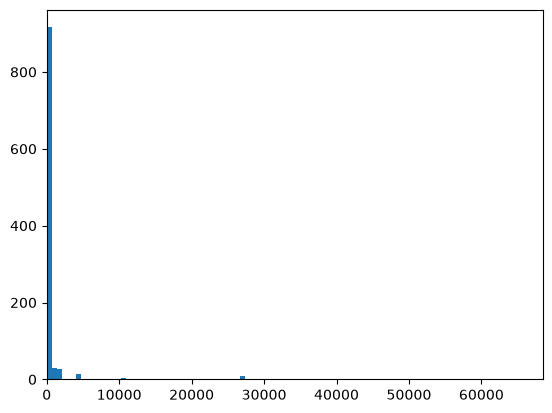

In [137]:
plt.hist(stat_sim, bins=100)
plt.xlim(0, max(stat_sim)+1)
plt.show()

9. Run the simulation with  number_of_bets to 5. What changes with the median and the mean results? 

In [146]:
stat_sim_5=simulation(100, number_of_bets = 5)
print(
    stat.mean(stat_sim_5),
    stat.median(stat_sim_5)
    )
## Median is closer to the mean than with multiple bets.

133.946946 121.5


10. Research what ergodicity means. Is the game ergodic or non-ergodic? 
I would says probably ergodic as based on the size of a sample the average values land very closely to each other, so with a large enough sample the averages seem like they are reproducible.